# DSC 411/511 Project
# Notebook 07: RQ5 (new): Rain or Surge? Explaining the Cause of Flood Claims and Finding Hotspots

**Class topics:** Lecture 09 (kernel density estimation, bandwidth, DBSCAN core/border/noise, choosing eps),
Lecture 05 (decision trees as readable rules), Lecture 06 (k-NN), Lecture 07 (multi-class evaluation),
plus spatial autocorrelation (Moran's I / LISA) as an extension.

---

**How this question was derived.** In RQ1-RQ2 the rain features and the coast-distance feature were among the most
useful. That raised a physical question: are claims driven by **rain** (pluvial flooding), by **rivers**, or by
**storm surge** from the sea? NFIP records the adjuster's answer in `causeOfDamage`. We use it as a label (never as a
feature) and ask whether the outside data can explain it.

**Published finding we reproduce and extend.** Nelson-Mercer et al. (2025, *npj Natural Hazards*) studied 216,994
NFIP claims **outside** the Special Flood Hazard Area (1978-2021) and report that **87.1% were pluvial-driven**. Our
data covers 2020-2025, a period that their study does not include.

> **RQ5. (a) Are claims outside the SFHA still mostly rain-driven in 2020-2025? (b) Can PRISM rain, HURDAT2 storm
> geometry and distance to the coast tell rain, river and surge claims apart? (c) Where are the hotspots of large
> losses, and are they inside or outside the mapped flood zones?**

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier, KernelDensity
from sklearn.cluster import DBSCAN
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score
import lightgbm as lgb

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
CAUSE_NAMES = {'1': 'surge_tidal', '2': 'river_overflow', '4': 'rain_accumulation'}
claims['cause_group'] = claims['causeOfDamage'].map(CAUSE_NAMES)
print('Cause of damage codes (all cleaned claims):')
print(claims['causeOfDamage'].value_counts(dropna=False).head(10).to_string())

Cause of damage codes (all cleaned claims):
causeOfDamage
4      122749
1       71764
2       41009
0       14404
NaN      1263
3         614
D         516
C          45
B          24
9           9


---
# Section 1: Part (a): Reproducing the "pluvial outside the SFHA" Finding

**Our proxy for "pluvial-driven".** Code 4, "accumulation of rainfall or snowmelt". Nelson-Mercer et al. used a
richer classification, so our share is not an exact replication; it is the closest test the public file allows.
We also validate the code with **PRISM**: if code 4 really means rain, those claims should have had much more rain.

In [2]:
claims['map_area'] = np.where(claims['in_special_flood_hazard_area'] == 1, 'inside SFHA (A, V zones)',
                              np.where(claims['flood_zone_group'] == 'X_moderate_or_minimal', 'outside SFHA (zone X, B, C)', 'other/unknown'))
known_cause = claims[claims['cause_group'].notna() & (claims['map_area'] != 'other/unknown')]
share_table = pd.crosstab(known_cause['map_area'], known_cause['cause_group'], normalize='index') * 100
share_table['claims'] = known_cause['map_area'].value_counts()
print('Cause shares (%) among claims with cause 1, 2 or 4:')
print(share_table.round(1).to_string())

all_coded = claims[claims['map_area'] == 'outside SFHA (zone X, B, C)']
print(f"\nOutside the SFHA, share coded 'rain accumulation' among ALL codes: {(all_coded['causeOfDamage'] == '4').mean() * 100:.1f}%")
by_year = (claims[claims['map_area'] == 'outside SFHA (zone X, B, C)'].groupby('loss_year')['causeOfDamage']
           .apply(lambda s: (s == '4').mean() * 100).round(1))
print('...by loss year (%):', by_year.to_dict())

Cause shares (%) among claims with cause 1, 2 or 4:
cause_group                  rain_accumulation  river_overflow  surge_tidal  claims
map_area                                                                           
inside SFHA (A, V zones)                  47.1            17.6         35.3  194579
outside SFHA (zone X, B, C)               75.9            16.4          7.6   40161

Outside the SFHA, share coded 'rain accumulation' among ALL codes: 66.1%
...by loss year (%): {2020: 62.3, 2021: 68.3, 2022: 49.8, 2023: 73.5, 2024: 68.0, 2025: 80.0}


Median external values by adjuster cause (validation of the label):
                   rain_3day_mm  storm_distance_km  coast_distance_km
cause_group                                                          
rain_accumulation         141.7              170.0                4.9
river_overflow            152.9              137.6               25.1
surge_tidal                76.8              143.9                1.8


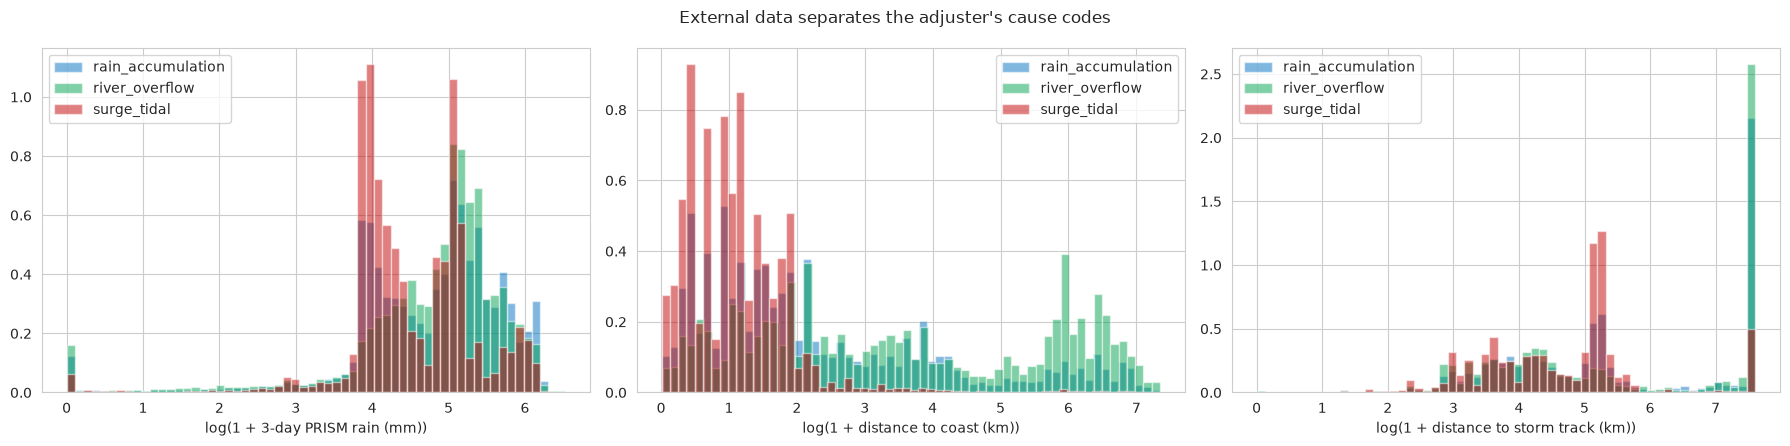

In [3]:
validation = known_cause.groupby('cause_group')[['rain_3day_mm', 'storm_distance_km', 'coast_distance_km']].median()
print('Median external values by adjuster cause (validation of the label):')
print(validation.round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, column, label in zip(axes, ['rain_3day_mm', 'coast_distance_km', 'storm_distance_km'],
                             ['3-day PRISM rain (mm)', 'distance to coast (km)', 'distance to storm track (km)']):
    for cause, color in zip(['rain_accumulation', 'river_overflow', 'surge_tidal'], ['#0070C0', '#00A050', '#C00000']):
        ax.hist(np.log1p(known_cause.loc[known_cause['cause_group'] == cause, column]), bins=60, alpha=0.5, density=True, color=color, label=cause)
    ax.set_xlabel(f'log(1 + {label})')
    ax.legend()
plt.suptitle('External data separates the adjuster\'s cause codes')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_cause_validation.png', dpi=120)
plt.show()

**Reading part (a).** Outside the SFHA, "rain accumulation" is still the dominant cause in 2020-2025: 75.9% of the
claims coded rain, river or surge (66.1% of all codes). This is below the 87.1% that Nelson-Mercer et al. report for
1978-2021. Two reasons: our label is the adjuster's cause code, not their streamflow method, and our period has big
surge hurricanes. The share drops to 49.8% in 2022 (Hurricane Ian). Inside the SFHA, surge is 35% of claims.
The PRISM rain and the coast distance agree with the codes: surge claims sit 1.8 km from the coast (median) and had the
least rain (77 mm), river claims are 25 km inland, and rain claims had 142 mm. The label is consistent enough to model.

---
# Section 2: Part (b): Can External Data Tell Rain, River and Surge Apart?

A three-class problem. Time split as always. We compare NFIP-only features with NFIP + event features.

In [4]:
TARGET = 'cause_group'
cause_data = claims[claims[TARGET].notna()].reset_index(drop=True)
train_claims = cause_data[cause_data['loss_year'].isin(TRAIN_YEARS)]
test_claims = cause_data[cause_data['loss_year'].isin(TEST_YEARS)]
print('Train class shares:', (train_claims[TARGET].value_counts(normalize=True) * 100).round(1).to_dict())
print('Test  class shares:', (test_claims[TARGET].value_counts(normalize=True) * 100).round(1).to_dict())

Train class shares: {'rain_accumulation': 53.1, 'surge_tidal': 26.2, 'river_overflow': 20.7}
Test  class shares: {'rain_accumulation': 50.8, 'surge_tidal': 36.1, 'river_overflow': 13.1}


## 2.1 A small decision tree: readable physical rules (Lecture 05)

We give the tree **only four external features**. If it can separate the causes with a few readable splits, the
physics is captured by the outside data.

|--- coast_distance_km <= 5.9
|   |--- storm_wind_proxy_at_claim_kt <= 44.6
|   |   |--- rain_3day_mm <= 84.1
|   |   |   |--- class: surge_tidal
|   |   |--- rain_3day_mm >  84.1
|   |   |   |--- class: rain_accumulation
|   |--- storm_wind_proxy_at_claim_kt >  44.6
|   |   |--- rain_3day_mm <= 161.9
|   |   |   |--- class: surge_tidal
|   |   |--- rain_3day_mm >  161.9
|   |   |   |--- class: surge_tidal
|--- coast_distance_km >  5.9
|   |--- coast_distance_km <= 89.6
|   |   |--- storm_distance_km <= 106.1
|   |   |   |--- class: river_overflow
|   |   |--- storm_distance_km >  106.1
|   |   |   |--- class: rain_accumulation
|   |--- coast_distance_km >  89.6
|   |   |--- storm_wind_proxy_at_claim_kt <= 28.3
|   |   |   |--- class: river_overflow
|   |   |--- storm_wind_proxy_at_claim_kt >  28.3
|   |   |   |--- class: rain_accumulation



Test macro-F1 with 4 physical features and depth 3: 0.473


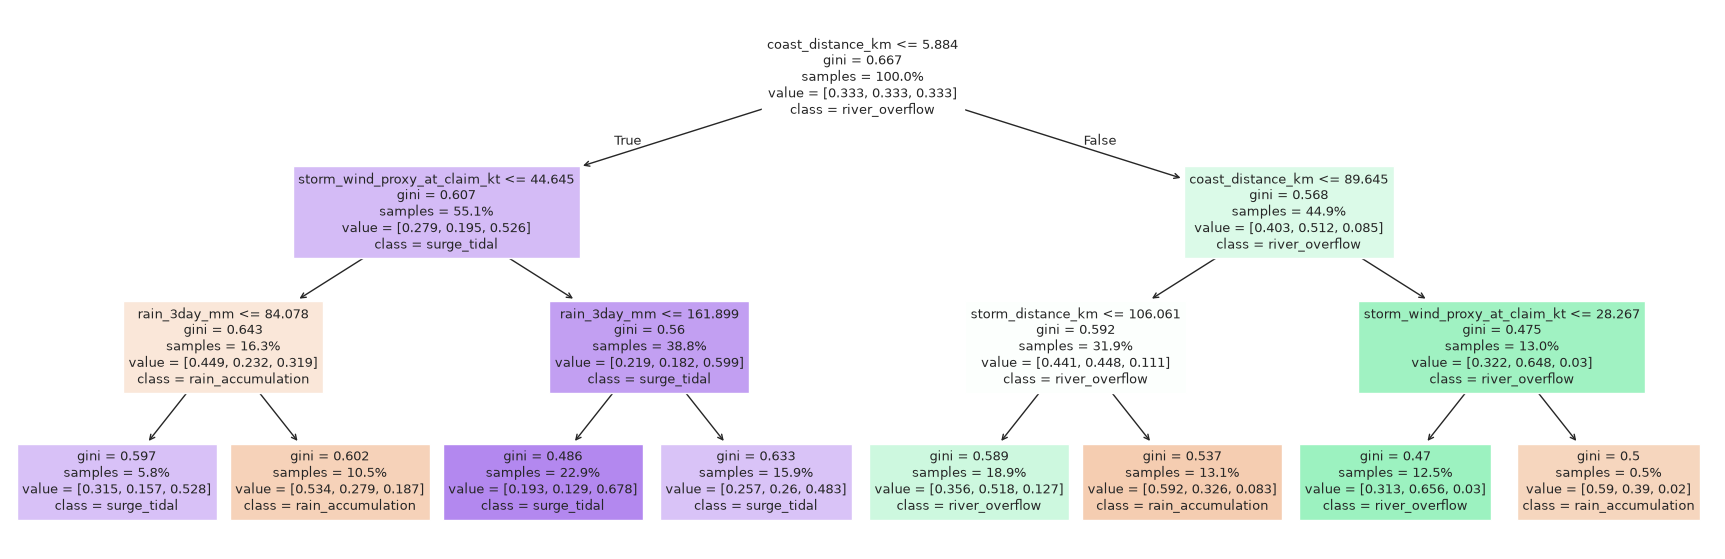

In [5]:
PHYSICAL_FEATURES = ['coast_distance_km', 'rain_3day_mm', 'storm_distance_km', 'storm_wind_proxy_at_claim_kt']
check_no_leakage(PHYSICAL_FEATURES)
physical_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, class_weight='balanced', random_state=SEED)
physical_tree.fit(train_claims[PHYSICAL_FEATURES], train_claims[TARGET])
tree_predictions = physical_tree.predict(test_claims[PHYSICAL_FEATURES])
print(export_text(physical_tree, feature_names=PHYSICAL_FEATURES, decimals=1))
print(f'Test macro-F1 with 4 physical features and depth 3: {f1_score(test_claims[TARGET], tree_predictions, average="macro"):.3f}')

fig, ax = plt.subplots(figsize=(22, 7))
plot_tree(physical_tree, feature_names=PHYSICAL_FEATURES, class_names=physical_tree.classes_, filled=True, proportion=True, fontsize=9, ax=ax)
plt.savefig(FIGURE_DIR / '07_cause_tree.png', dpi=100)
plt.show()

## 2.2 Full comparison: NFIP only vs NFIP + external

In [6]:
def fit_cause_lightgbm(train_rows, numeric, categorical):
    model = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.7, class_weight='balanced', random_state=SEED, verbose=-1)
    model.fit(to_category_frame(train_rows, numeric, categorical), train_rows[TARGET])
    return model


comparison_rows = []
predictions_by_set = {}
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    check_no_leakage(numeric + categorical)
    model = fit_cause_lightgbm(train_claims, numeric, categorical)
    predicted = model.predict(to_category_frame(test_claims, numeric, categorical))
    predictions_by_set[set_name] = predicted
    comparison_rows.append({'model': 'LightGBM', 'feature_set': set_name, 'macro_F1': f1_score(test_claims[TARGET], predicted, average='macro'),
                            'balanced_accuracy': balanced_accuracy_score(test_claims[TARGET], predicted)})
knn_sample = train_claims.sample(40_000, random_state=SEED)
for set_name in ['A. NFIP only', 'B. NFIP + event (PRISM, HURDAT2, coast)']:
    numeric, categorical = FEATURE_SETS[set_name]
    knn = Pipeline([('prep', make_preprocessor(numeric, categorical)), ('model', KNeighborsClassifier(n_neighbors=51, n_jobs=4))])
    knn.fit(knn_sample, knn_sample[TARGET])
    predicted = knn.predict(test_claims.sample(20_000, random_state=SEED))
    truth = test_claims.sample(20_000, random_state=SEED)[TARGET]
    comparison_rows.append({'model': 'k-NN (k=51, 40k sample)', 'feature_set': set_name, 'macro_F1': f1_score(truth, predicted, average='macro'),
                            'balanced_accuracy': balanced_accuracy_score(truth, predicted)})
comparison_rows.append({'model': 'Decision tree depth 3', 'feature_set': '4 physical external features only',
                        'macro_F1': f1_score(test_claims[TARGET], tree_predictions, average='macro'),
                        'balanced_accuracy': balanced_accuracy_score(test_claims[TARGET], tree_predictions)})
comparison_table = pd.DataFrame(comparison_rows).round(3)
comparison_table.to_csv(TABLE_DIR / '07_rq5_cause_models.csv', index=False)
print(comparison_table.to_string(index=False))

                  model                             feature_set  macro_F1  balanced_accuracy
               LightGBM                            A. NFIP only     0.581              0.603
               LightGBM B. NFIP + event (PRISM, HURDAT2, coast)     0.581              0.620
               LightGBM    C. NFIP + event + context (ACS, NRI)     0.588              0.627
k-NN (k=51, 40k sample)                            A. NFIP only     0.493              0.482
k-NN (k=51, 40k sample) B. NFIP + event (PRISM, HURDAT2, coast)     0.518              0.508
  Decision tree depth 3       4 physical external features only     0.473              0.554


                   precision    recall  f1-score   support

rain_accumulation      0.754     0.405     0.527     51621
   river_overflow      0.538     0.601     0.568     13258
      surge_tidal      0.543     0.874     0.670     36638

         accuracy                          0.600    101517
        macro avg      0.612     0.627     0.588    101517
     weighted avg      0.650     0.600     0.584    101517



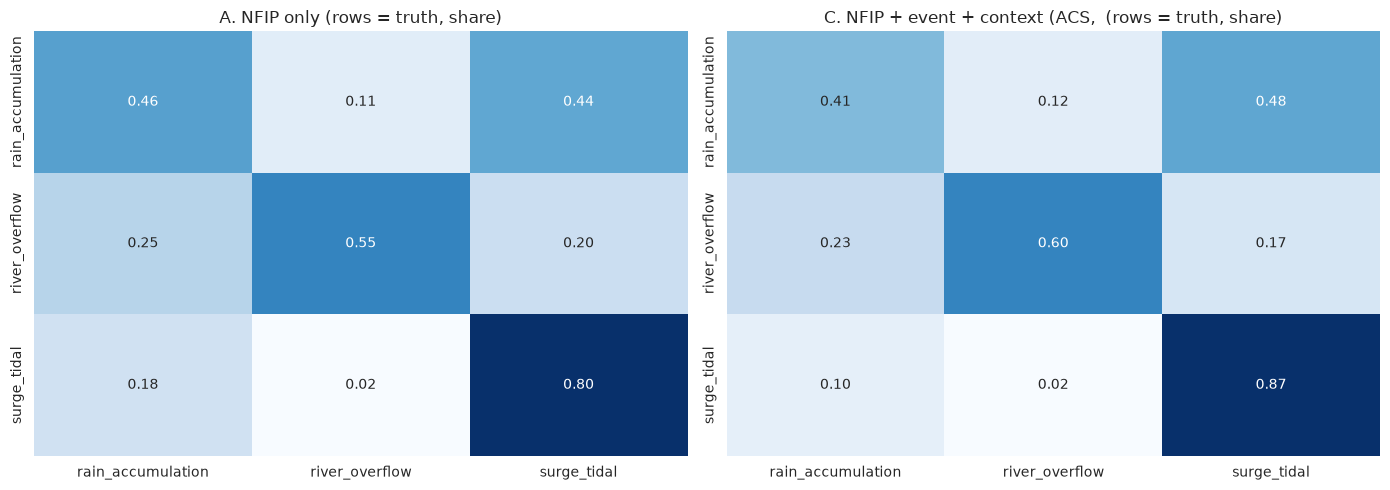

In [7]:
best_predictions = predictions_by_set['C. NFIP + event + context (ACS, NRI)']
print(classification_report(test_claims[TARGET], best_predictions, digits=3))
labels = ['rain_accumulation', 'river_overflow', 'surge_tidal']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, set_name in zip(axes, ['A. NFIP only', 'C. NFIP + event + context (ACS, NRI)']):
    matrix = confusion_matrix(test_claims[TARGET], predictions_by_set[set_name], labels=labels, normalize='true')
    sns.heatmap(matrix, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f'{set_name[:32]} (rows = truth, share)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_cause_confusion.png', dpi=120)
plt.show()

**Reading part (b).** This result surprised us. **The external features do not improve LightGBM** (macro-F1 0.581
NFIP-only, 0.581 with event data, 0.588 with context). The reason: NFIP already contains latitude, longitude and the
flood zone (V zone = coast), which together say most of what coast distance says. The external data does help the
simpler k-NN (0.493 -> 0.518). A depth-3 tree on **only four** external features (coast distance, storm wind, storm
distance, rain) reaches macro-F1 0.473 with rules a person can read: "within 6 km of the coast -> surge, unless
rain was heavy and the wind weak; further inland and close to the track -> river; far from the track -> rain".
Per class: surge is found well (recall 0.87), river is moderate, and rain claims are often confused with surge
(recall 0.41), because in a hurricane a coastal house gets both rain and surge.

---
# Section 3: Part (c): Where Are the Hotspots? Kernel Density (Lecture 09)

KDE puts a small bump (kernel) on every claim and adds them up. The **bandwidth** is the width of each bump: too small
gives a spiky map of single points, too large blurs everything into one blob (Lecture 09, Section 2).
We compare large-loss density with all-claim density, which shows where large losses are **over-represented**.

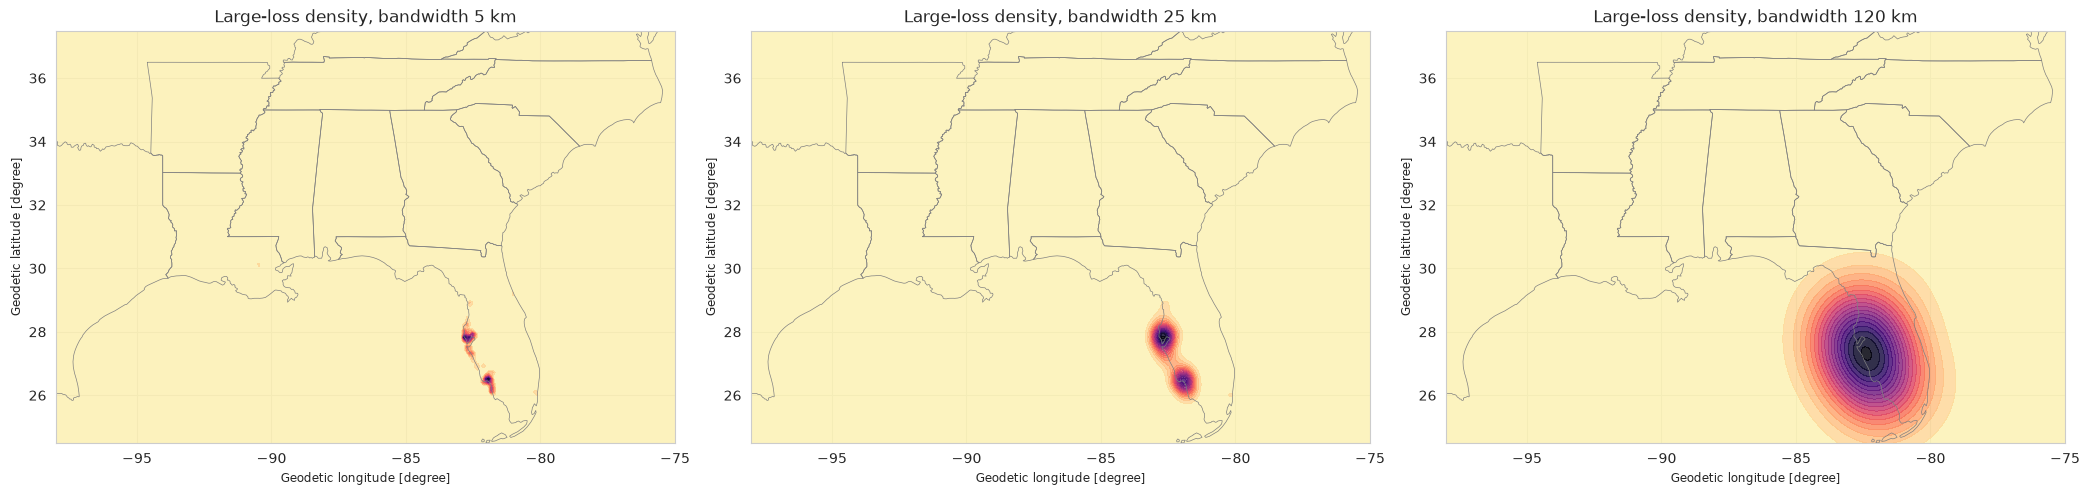

In [8]:
states = gpd.read_file(f'zip://{RAW_DIR / "boundaries" / "cb_2023_us_state_20m.zip"}')
southeast = states[states['STUSPS'].isin(['FL', 'GA', 'AL', 'MS', 'LA', 'TX', 'SC', 'NC', 'TN', 'VA', 'AR', 'KY'])]
large_claims = claims[claims['large_loss_flag'] == 1]
grid_longitude, grid_latitude = np.meshgrid(np.linspace(-98, -75, 230), np.linspace(24.5, 37.5, 130))
grid_points = np.radians(np.column_stack([grid_latitude.ravel(), grid_longitude.ravel()]))


def kde_surface(points, bandwidth_km):
    model = KernelDensity(bandwidth=bandwidth_km / 6371.0, metric='haversine', kernel='gaussian')
    model.fit(np.radians(points[['latitude', 'longitude']].sample(min(30_000, len(points)), random_state=SEED).values))
    return np.exp(model.score_samples(grid_points)).reshape(grid_latitude.shape)


fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, bandwidth in zip(axes, [5, 25, 120]):
    density = kde_surface(large_claims, bandwidth)
    southeast.boundary.plot(ax=ax, color='grey', linewidth=0.5)
    ax.contourf(grid_longitude, grid_latitude, density, levels=20, cmap='magma_r', alpha=0.85)
    ax.set_title(f'Large-loss density, bandwidth {bandwidth} km')
    ax.set_xlim(-98, -75)
    ax.set_ylim(24.5, 37.5)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_kde_bandwidth.png', dpi=110)
plt.show()

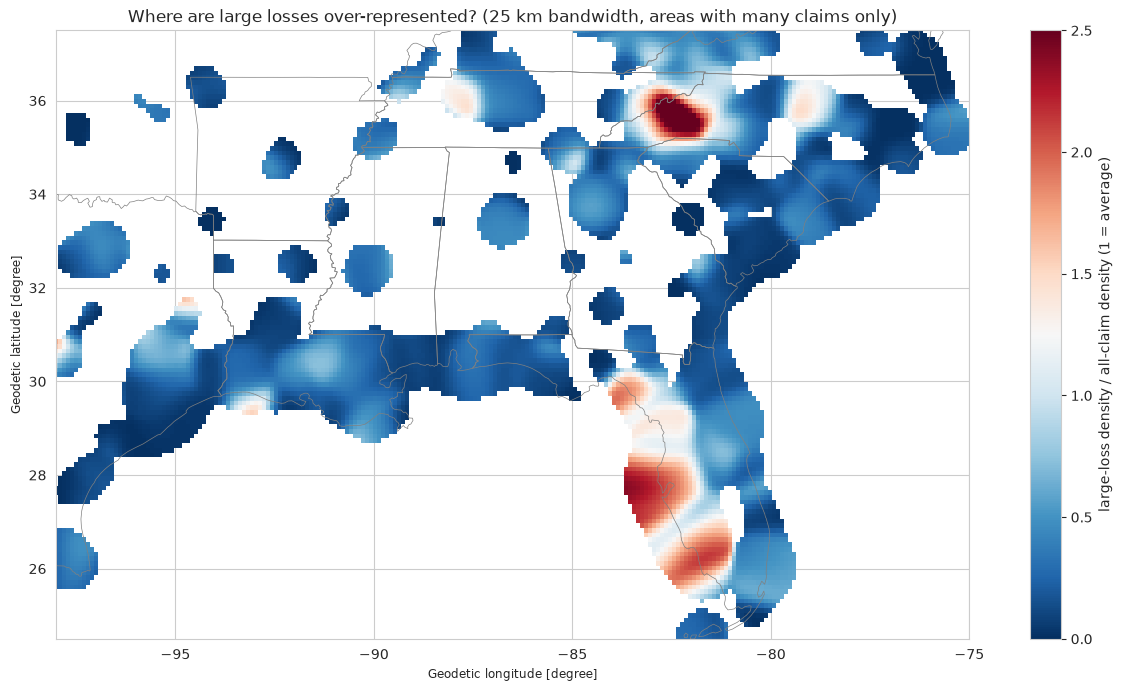

In [9]:
all_density = kde_surface(claims, 25)
large_density = kde_surface(large_claims, 25)
relative_risk = np.where(all_density > np.quantile(all_density, 0.70), large_density / all_density, np.nan)
fig, ax = plt.subplots(figsize=(13, 7))
southeast.boundary.plot(ax=ax, color='grey', linewidth=0.5)
image = ax.pcolormesh(grid_longitude, grid_latitude, relative_risk, cmap='RdBu_r', vmin=0, vmax=2.5, shading='auto')
plt.colorbar(image, ax=ax, label='large-loss density / all-claim density (1 = average)')
ax.set_title('Where are large losses over-represented? (25 km bandwidth, areas with many claims only)')
ax.set_xlim(-98, -75)
ax.set_ylim(24.5, 37.5)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_kde_relative_risk.png', dpi=110)
plt.show()

---
# Section 4: DBSCAN Hotspots (Lecture 09, Sections 5-8)

We run DBSCAN on the **0.1-degree points**, weighted by the number of large-loss claims at each point. With the
haversine metric, `eps` is a real distance. A point is a **core** point if at least `min_samples` large-loss claims
lie within `eps`. This is exactly the setting where DBSCAN wins (Lecture 09, Section 8): hotspots have irregular
shapes along coasts and rivers, and we do not know how many there are.

In [10]:
large_points = large_claims.groupby(['latitude', 'longitude']).agg(large_claims=('id', 'size'),
                                                                   share_outside_sfha=('in_special_flood_hazard_area', lambda s: 1 - s.mean()),
                                                                   share_rain_cause=('causeOfDamage', lambda s: (s == '4').mean()),
                                                                   share_surge_cause=('causeOfDamage', lambda s: (s == '1').mean())).reset_index()
# Choosing eps and min_samples (Lecture 09, Section 6). The claim points sit on a 0.1-degree grid (about 10-11 km),
# so eps decides how many grid steps can link. We first try a small grid of settings and look at the number of hotspots,
# the share of large losses in the biggest one, and the share left as noise.
sensitivity_rows = []
for eps_try in [12, 15, 20]:
    for min_try in [150, 300, 600]:
        labels_try = DBSCAN(eps=eps_try / 6371.0, min_samples=min_try, metric='haversine', algorithm='ball_tree').fit_predict(
            np.radians(large_points[['latitude', 'longitude']]), sample_weight=large_points['large_claims'])
        claims_per_label = large_points['large_claims'].groupby(labels_try).sum()
        hotspot_claims = claims_per_label[claims_per_label.index >= 0]
        sensitivity_rows.append({'eps_km': eps_try, 'min_large_claims': min_try, 'hotspots': len(hotspot_claims),
                                 'largest_hotspot_%': hotspot_claims.max() / large_points['large_claims'].sum() * 100 if len(hotspot_claims) else 0,
                                 'noise_%': claims_per_label.get(-1, 0) / large_points['large_claims'].sum() * 100})
print(pd.DataFrame(sensitivity_rows).round(1).to_string(index=False))

# With eps of 15-20 km, DBSCAN "chains" along the Florida Gulf coast: neighbouring dense cells link into one hotspot
# that holds about 76% of all large losses. With eps = 12 km only directly neighbouring grid cells link, so separate
# storm areas stay separate. We use eps = 12 km and min_samples = 150.
EPS_KM, MIN_LARGE_CLAIMS = 12, 150
dbscan = DBSCAN(eps=EPS_KM / 6371.0, min_samples=MIN_LARGE_CLAIMS, metric='haversine', algorithm='ball_tree')
large_points['hotspot'] = dbscan.fit_predict(np.radians(large_points[['latitude', 'longitude']]), sample_weight=large_points['large_claims'])
core_mask = np.zeros(len(large_points), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
large_points['point_type'] = np.where(core_mask, 'core', np.where(large_points['hotspot'] >= 0, 'border', 'noise'))
print(f'eps = {EPS_KM} km, min_samples = {MIN_LARGE_CLAIMS} large-loss claims')
print('Hotspots found:', large_points['hotspot'].max() + 1)
print(large_points.groupby('point_type')['large_claims'].sum().rename('large-loss claims').to_string())

hotspot_summary = (large_points[large_points['hotspot'] >= 0].groupby('hotspot')
                   .apply(lambda g: pd.Series({'large_loss_claims': g['large_claims'].sum(),
                                               'centre_lat': np.average(g['latitude'], weights=g['large_claims']),
                                               'centre_lon': np.average(g['longitude'], weights=g['large_claims']),
                                               'share_outside_SFHA_%': np.average(g['share_outside_sfha'], weights=g['large_claims']) * 100,
                                               'share_rain_cause_%': np.average(g['share_rain_cause'], weights=g['large_claims']) * 100,
                                               'share_surge_cause_%': np.average(g['share_surge_cause'], weights=g['large_claims']) * 100}))
                   .sort_values('large_loss_claims', ascending=False))
main_event = (large_claims.merge(large_points[['latitude', 'longitude', 'hotspot']], on=['latitude', 'longitude'])
              .groupby('hotspot')['event_group'].agg(lambda s: s.value_counts().index[0]))
hotspot_summary['main_event'] = main_event
hotspot_summary.round(1).to_csv(TABLE_DIR / '07_rq5_dbscan_hotspots.csv')
print(hotspot_summary.round(1).head(15).to_string())

 eps_km  min_large_claims  hotspots  largest_hotspot_%  noise_%
     12               150         8               46.5     18.4
     12               300         5               33.7     22.7
     12               600         3               33.4     28.6
     15               150        10               76.0     15.3
     15               300         4               76.0     19.7
     15               600         3               42.3     26.0
     20               150         9               76.1     14.8
     20               300         4               76.0     19.6
     20               600         3               42.4     24.5
eps = 12 km, min_samples = 150 large-loss claims
Hotspots found: 8
point_type
border      738
core      23181
noise      5383
         large_loss_claims  centre_lat  centre_lon  share_outside_SFHA_%  share_rain_cause_%  share_surge_cause_%                     main_event
hotspot                                                                                  

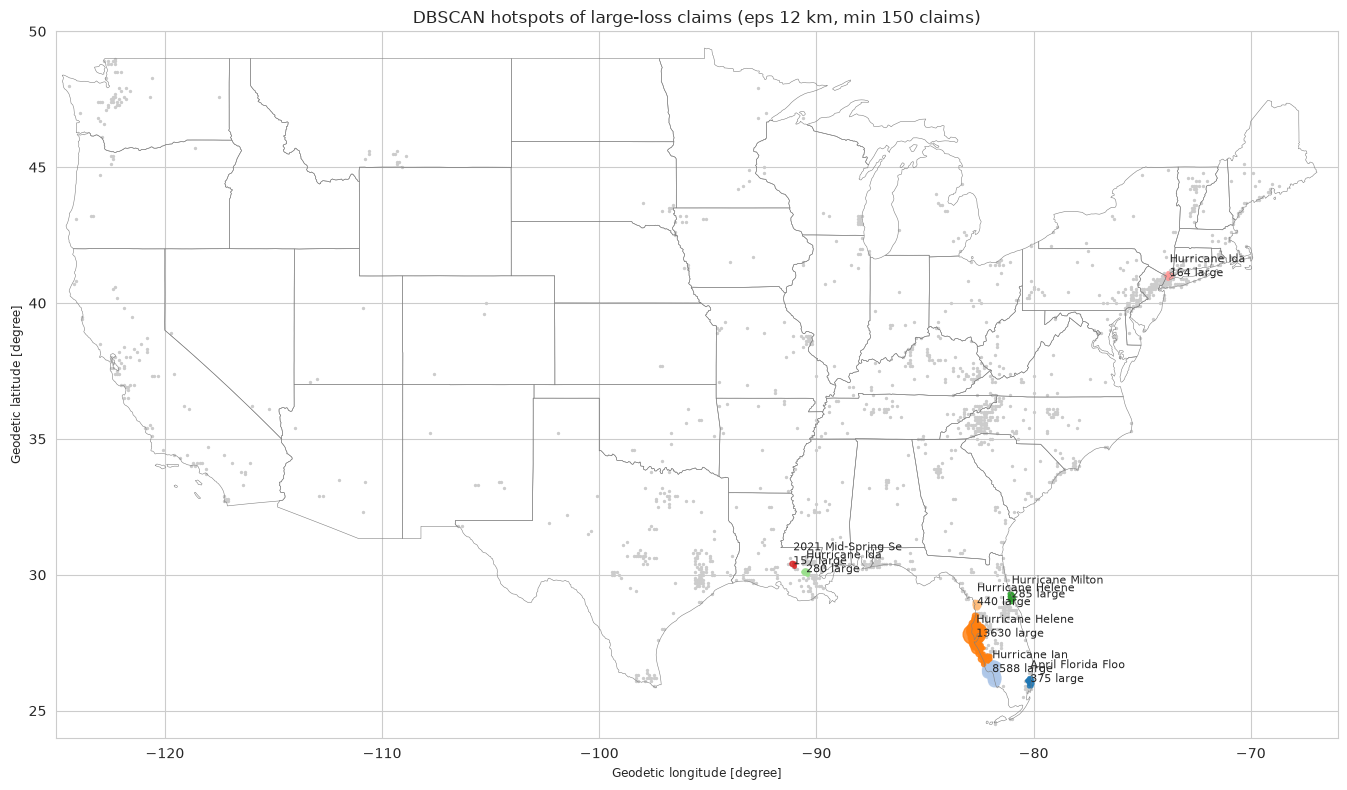

In [11]:
fig, ax = plt.subplots(figsize=(15, 8))
states[~states['STUSPS'].isin(['AK', 'HI', 'PR'])].boundary.plot(ax=ax, color='grey', linewidth=0.4)
noise = large_points[large_points['hotspot'] < 0]
ax.scatter(noise['longitude'], noise['latitude'], s=2, color='#cccccc', label='noise')
hotspot_colors = sns.color_palette('tab20', max(1, large_points['hotspot'].max() + 1))
for hotspot_id, group in large_points[large_points['hotspot'] >= 0].groupby('hotspot'):
    ax.scatter(group['longitude'], group['latitude'], s=4 + group['large_claims'] / 10, color=hotspot_colors[hotspot_id % 20], alpha=0.8)
    if hotspot_id in hotspot_summary.head(10).index:
        row = hotspot_summary.loc[hotspot_id]
        ax.annotate(f"{str(row['main_event'])[:18]}\n{int(row['large_loss_claims'])} large", (row['centre_lon'], row['centre_lat']), fontsize=8)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'DBSCAN hotspots of large-loss claims (eps {EPS_KM} km, min {MIN_LARGE_CLAIMS} claims)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_dbscan_hotspots.png', dpi=110)
plt.show()

**Reading the hotspots.** The sensitivity table shows the classic DBSCAN "chaining" problem (Lecture 09): with
eps of 15-20 km, the Florida Gulf coast links into one hotspot holding 76% of all large losses. With eps = 12 km we
get 8 hotspots, and 18% of large losses are noise (scattered). Each hotspot belongs to one or two storms:
- **Tampa Bay / Pinellas (Helene, 13,630 large losses)** and **Fort Myers / Naples (Ian, 8,588)**: about half are
  coded surge, and almost all are inside the SFHA (only 1-2% outside). These two hold 76% of the hotspot claims.
- **Fort Lauderdale (April 2023 flooding, 375)**: 97% coded rain accumulation, the clearest **pluvial** hotspot,
  with no hurricane at all.
- **Daytona / Flagler (Milton, 285)**: 30% of large losses outside the SFHA, the highest share of any hotspot.
- **Louisiana (Ida; 2021 spring storms)** and **New York / New Jersey (Ida's remnant rain)**: rain-coded, almost no
  surge, and 10-20% outside the SFHA.
The inland Helene damage in western North Carolina is too spread out for min_samples = 150 within 12 km, but the KDE
relative-risk map above shows it as the strongest inland area of over-represented large losses.

---
# Section 5: Extension: Spatial Autocorrelation of County Loss Rates (Moran's I, LISA)

DBSCAN found dense groups of points. Moran's I asks a different question: do **neighbouring counties have similar
large-loss rates**? I near 0 = random pattern, I > 0 = similar values cluster. LISA breaks I into a local value per
county, giving "hot spots" (High-High) and "cold spots" (Low-Low).

Counties with >= 20 claims and at least one neighbour: 586
Moran's I for large-loss rate = 0.448  (expected under randomness -0.002), permutation p = 0.002
lisa
not significant         473
Low-Low (cold spot)      53
High-High (hot spot)     40
Low-High                 11
High-Low                  9


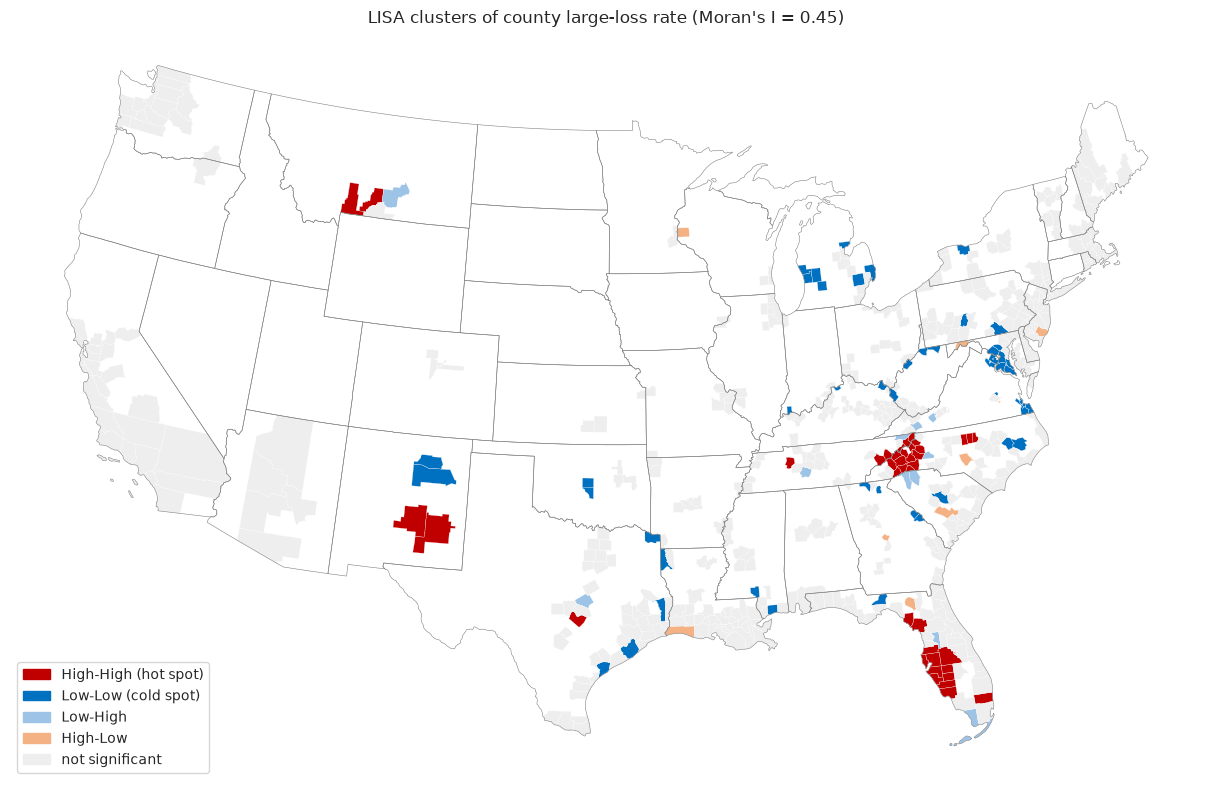

In [12]:
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local

county_map = gpd.read_parquet(PROCESSED_DIR / 'county_summary_map.parquet')
county_map = county_map[county_map['claims'] >= 20].reset_index(drop=True)
weights = Queen.from_dataframe(county_map, use_index=False, silence_warnings=True)
weights.transform = 'r'
connected = np.array([len(weights.neighbors[i]) > 0 for i in range(len(county_map))])
county_map = county_map[connected].reset_index(drop=True)
weights = Queen.from_dataframe(county_map, use_index=False, silence_warnings=True)
weights.transform = 'r'
moran = Moran(county_map['large_loss_rate'].fillna(0).values, weights, permutations=499)
print(f'Counties with >= 20 claims and at least one neighbour: {len(county_map)}')
print(f"Moran's I for large-loss rate = {moran.I:.3f}  (expected under randomness {moran.EI:.3f}), permutation p = {moran.p_sim:.3f}")

local_moran = Moran_Local(county_map['large_loss_rate'].fillna(0).values, weights, permutations=499, seed=SEED)
quadrant_names = {1: 'High-High (hot spot)', 2: 'Low-High', 3: 'Low-Low (cold spot)', 4: 'High-Low'}
county_map['lisa'] = [quadrant_names[q] if p < 0.05 else 'not significant' for q, p in zip(local_moran.q, local_moran.p_sim)]
print(county_map['lisa'].value_counts().to_string())
lisa_colors = {'High-High (hot spot)': '#C00000', 'Low-Low (cold spot)': '#0070C0', 'Low-High': '#9DC3E6', 'High-Low': '#F4B183', 'not significant': '#eeeeee'}
fig, ax = plt.subplots(figsize=(15, 8))
for label, color in lisa_colors.items():
    subset = county_map[county_map['lisa'] == label]
    if len(subset):
        subset.plot(ax=ax, color=color, edgecolor='white', linewidth=0.2, label=label)
states[~states['STUSPS'].isin(['AK', 'HI', 'PR'])].to_crs(county_map.crs).boundary.plot(ax=ax, color='grey', linewidth=0.4)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in lisa_colors.values()]
ax.legend(handles, lisa_colors.keys(), loc='lower left')
ax.set_axis_off()
ax.set_title(f"LISA clusters of county large-loss rate (Moran's I = {moran.I:.2f})")
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_lisa_large_loss.png', dpi=110)
plt.show()

In [13]:
results_rq5 = {'cause_share_by_map_area': share_table.round(2).reset_index().to_dict('records'),
               'outside_sfha_rain_share_all_codes_pct': float((all_coded['causeOfDamage'] == '4').mean() * 100),
               'cause_models': comparison_table.to_dict('records'), 'n_hotspots': int(large_points['hotspot'].max() + 1),
               'top_hotspots': hotspot_summary.round(1).head(10).reset_index().to_dict('records'),
               'morans_I': float(moran.I), 'morans_p': float(moran.p_sim)}
json.dump(results_rq5, open(TABLE_DIR / '07_rq5_results.json', 'w'), indent=2, default=str)

---
# Research Question -> Answer

> **RQ5 (a). Are claims outside the SFHA still mostly rain-driven in 2020-2025?**

**Yes, but less than before.** 75.9% of the outside-SFHA claims coded rain, river or surge are "rain accumulation"
(66.1% of all codes), against 87.1% in Nelson-Mercer et al. for 1978-2021. The share falls to 49.8% in 2022 (Ian).
PRISM rain and coast distance confirm that the adjuster's codes are physically consistent (surge: 1.8 km from the
coast, 77 mm rain; rain: 142 mm).

> **RQ5 (b). Can PRISM, HURDAT2 and coast distance tell rain, river and surge claims apart?**

**Partly, and the external data is not what makes it work.** LightGBM reaches macro-F1 about 0.58 (balanced accuracy
0.60-0.63) with or without external features, because NFIP latitude, longitude and flood zone already encode the coast.
External data helps k-NN (0.49 -> 0.52), and four external features alone give a readable depth-3 tree (macro-F1
0.47). Surge is recognised well (recall 0.87); rain is often confused with surge in hurricanes.

> **RQ5 (c). Where are the large-loss hotspots?**

Large losses are strongly clustered. County large-loss rates have **Moran's I = 0.45** (p = 0.002), with 40 High-High
counties (southwest Florida Gulf coast, western North Carolina / east Tennessee, and smaller groups in New Mexico and
Montana) and 53 Low-Low counties. DBSCAN (eps 12 km) finds 8 storm-specific hotspots. The two biggest (Tampa Bay /
Helene and Fort Myers / Ian) hold 76% of the hotspot claims; they are half surge and almost entirely inside the SFHA.
Smaller hotspots (Fort Lauderdale 2023, Louisiana, New York / New Jersey) are rain-driven, and there 10-30% of large
losses are outside the mapped flood zone. **Addition to the published work:** pluvial large losses are not only a
"zone X, small claim" story; they form their own urban hotspots.